# **OilyGiant — Oil Well Profitability & Risk Analysis**

# **1. Introdução**

A OilyGiant pretende expandir suas operações por meio do desenvolvimento de novos poços de petróleo. O desafio consiste em identificar, entre três regiões candidatas, aquela que oferece a melhor combinação entre retorno financeiro esperado e risco de prejuízo.

A análise utiliza dados geológicos de poços existentes para estimar o volume de reservas de novos locais. Em seguida, as previsões orientam a seleção dos 200 poços mais promissores em cada região. Por fim, o método de *Bootstrapping* simula cenários de investimento para quantificar a incerteza dos resultados.

### **Objetivo**

Recomendar uma região para investimento, respeitando o limite de risco de prejuízo inferior a **2,5%** e considerando o orçamento e as condições comerciais estabelecidas.

### **Fluxo de trabalho**

1. Carregar e validar os dados das três regiões.
2. Treinar modelos de regressão linear e avaliar as previsões.
3. Definir os parâmetros financeiros e calcular o ponto de equilíbrio.
4. Estimar o lucro dos 200 poços com maiores reservas previstas.
5. Aplicar *Bootstrapping* para estimar lucro médio, intervalo de confiança de 95% e risco de prejuízo.
6. Recomendar a região que atende aos critérios de investimento.

### **Dataset**

Cada arquivo (`geo_data_0.csv`, `geo_data_1.csv` e `geo_data_2.csv`) contém 100.000 registros e as seguintes variáveis:

- `id`: identificador do poço;
- `f0`, `f1`, `f2`: características geológicas utilizadas como preditoras;
- `product`: volume de reservas em milhares de barris (variável-alvo).

**Restrição metodológica:** será utilizada regressão linear, conforme especificado no projeto. A coluna `id` será excluída do treinamento por ser apenas um identificador.

# **2. Carregamento e validação de dados**

Os três conjuntos de dados são carregados a partir da pasta `data/`. A inspeção verifica dimensões, tipos de dados, valores ausentes, duplicatas e estatísticas descritivas.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

RANDOM_STATE = 12345
DATA_DIR = Path(".")

regions = {
    "Region 0": pd.read_csv(DATA_DIR / "geo_data_0.csv"),
    "Region 1": pd.read_csv(DATA_DIR / "geo_data_1.csv"),
    "Region 2": pd.read_csv(DATA_DIR / "geo_data_2.csv"),
}

for region_name, data in regions.items():
    print(f"{region_name}: {data.shape[0]:,} rows × {data.shape[1]} columns")

Region 0: 100,000 rows × 5 columns
Region 1: 100,000 rows × 5 columns
Region 2: 100,000 rows × 5 columns


In [5]:
validation_summary = []

for region_name, data in regions.items():
    validation_summary.append({
        "Region": region_name,
        "Rows": len(data),
        "Columns": data.shape[1],
        "Missing values": int(data.isna().sum().sum()),
        "Duplicate rows": int(data.duplicated().sum()),
        "Mean reserves (thousand barrels)": data["product"].mean(),
    })

validation_df = pd.DataFrame(validation_summary)
display(validation_df.round(2))

,Region,Rows,Columns,Missing values,Duplicate rows,Mean reserves (thousand barrels)
0,Region 0,100000,5,0,0,92.50
1,Region 1,100000,5,0,0,68.82
2,Region 2,100000,5,0,0,95.00


In [6]:
for region_name, data in regions.items():
    print(f"\n{region_name}")
    display(data.head())
    display(data.dtypes.rename("Data type").to_frame())


Region 0


,id,f0,f1,f2,product
0,txEyH,0.705745,-0.497823,1.221170,105.280062
1,2acmU,1.334711,-0.340164,4.365080,73.037750
2,409Wp,1.022732,0.151990,1.419926,85.265647
3,iJLyR,-0.032172,0.139033,2.978566,168.620776
4,Xdl7t,1.988431,0.155413,4.751769,154.036647


,Data type
id,object
f0,float64
f1,float64
f2,float64
product,float64



Region 1


,id,f0,f1,f2,product
0,kBEdx,-15.001348,-8.276000,-0.005876,3.179103
1,62mP7,14.272088,-3.475083,0.999183,26.953261
2,vyE1P,6.263187,-5.948386,5.001160,134.766305
3,KcrkZ,-13.081196,-11.506057,4.999415,137.945408
4,AHL4O,12.702195,-8.147433,5.004363,134.766305


,Data type
id,object
f0,float64
f1,float64
f2,float64
product,float64



Region 2


,id,f0,f1,f2,product
0,fwXo0,-1.146987,0.963328,-0.828965,27.758673
1,WJtFt,0.262778,0.269839,-2.530187,56.069697
2,ovLUW,0.194587,0.289035,-5.586433,62.871910
3,q6cA6,2.236060,-0.553760,0.930038,114.572842
4,WPMUX,-0.515993,1.716266,5.899011,149.600746


,Data type
id,object
f0,float64
f1,float64
f2,float64
product,float64


### **2.1 Avaliação da qualidade dos dados**

A verificação inicial permite confirmar a integridade estrutural dos arquivos antes da modelagem. Os identificadores não serão usados como variáveis preditoras. As características `f0`, `f1` e `f2` serão mantidas, e `product` será o alvo da regressão.

A regressão linear não exige padronização obrigatória para este fluxo: as variáveis são numéricas e o objetivo é comparar previsões e erros sob a mesma metodologia em cada região.

# **3. Modelagem de regressão linear**

Para cada região, os dados são divididos em 75% para treinamento e 25% para validação. O modelo é treinado exclusivamente com `f0`, `f1` e `f2`. As previsões e os valores reais do conjunto de validação são armazenados juntos para as etapas financeiras.

In [7]:
def train_and_evaluate(data, random_state=RANDOM_STATE):
    features = data[["f0", "f1", "f2"]]
    target = data["product"]

    features_train, features_valid, target_train, target_valid = train_test_split(
        features,
        target,
        test_size=0.25,
        random_state=random_state,
    )

    model = LinearRegression()
    model.fit(features_train, target_train)
    predictions = model.predict(features_valid)

    results = pd.DataFrame({
        "actual": target_valid.to_numpy(),
        "predicted": predictions,
    }, index=target_valid.index)

    rmse = mean_squared_error(target_valid, predictions) ** 0.5

    metrics = {
        "Mean predicted reserves": predictions.mean(),
        "RMSE": rmse,
    }
    return model, results, metrics

In [8]:
models = {}
validation_results = {}
model_metrics = {}

for region_name, data in regions.items():
    model, results, metrics = train_and_evaluate(data)
    models[region_name] = model
    validation_results[region_name] = results
    model_metrics[region_name] = metrics

model_comparison = pd.DataFrame(model_metrics).T
model_comparison.index.name = "Region"
display(model_comparison.round(2))

,Mean predicted reserves,RMSE
Region,,
Region 0,92.59,37.58
Region 1,68.73,0.89
Region 2,94.97,40.03


### **3.1 Avaliação do modelo**

O RMSE mede a magnitude média do erro de previsão, na mesma unidade da variável-alvo (milhares de barris); quanto menor, melhor. A média prevista descreve o volume médio estimado no conjunto de validação, mas não deve ser usada isoladamente para escolher a região.

A Região 1 apresenta erro de previsão muito menor que as demais, o que indica maior previsibilidade neste conjunto de dados. As Regiões 0 e 2 apresentam volumes médios previstos maiores, mas também erros mais elevados. A decisão de investimento será baseada na análise de lucro e risco, não apenas nessas métricas.

# **4. Premissas de negócio e análise de ponto de equilíbrio**

Os parâmetros financeiros são definidos separadamente para tornar os cálculos transparentes e facilitar a revisão das premissas.

In [9]:
TOTAL_BUDGET = 100_000_000
WELLS_TO_DEVELOP = 200
REVENUE_PER_UNIT = 4_500
CANDIDATES_PER_SAMPLE = 500
BOOTSTRAP_SAMPLES = 1_000
MAX_LOSS_RISK = 2.5

break_even_volume = TOTAL_BUDGET / (WELLS_TO_DEVELOP * REVENUE_PER_UNIT)

print(f"Break-even reserves per well: {break_even_volume:.2f} thousand barrels")

Break-even reserves per well: 111.11 thousand barrels


In [10]:
mean_reserves = pd.Series({
    region_name: data["product"].mean()
    for region_name, data in regions.items()
}, name="Mean reserves (thousand barrels)")

break_even_comparison = mean_reserves.to_frame()
break_even_comparison["Break-even volume"] = break_even_volume
break_even_comparison["Below break-even"] = (
    break_even_comparison["Mean reserves (thousand barrels)"] < break_even_volume
)
display(break_even_comparison.round(2))

,Mean reserves (thousand barrels),Break-even volume,Below break-even
Region 0,92.50,111.11,True
Region 1,68.82,111.11,True
Region 2,95.00,111.11,True


### **4.1 Interpretação**

O ponto de equilíbrio é de aproximadamente **111,1 mil barris por poço**, considerando 200 poços, orçamento total de 100 milhões e receita de 4.500 por unidade de produto.

A média de reservas de cada região está abaixo desse patamar. Portanto, selecionar poços aleatoriamente não é uma estratégia adequada. A viabilidade depende da capacidade do modelo de classificar corretamente os poços com maior potencial produtivo.

# **5. Estimativa de lucro para os 200 poços mais bem classificados**

A função abaixo ordena os poços pela reserva prevista, seleciona os 200 maiores e calcula a receita usando as reservas reais desses poços. O lucro é a receita total menos o orçamento de desenvolvimento.

In [11]:
def calculate_profit(results, wells_count=WELLS_TO_DEVELOP):
    top_wells = results.nlargest(wells_count, "predicted")
    total_reserves = top_wells["actual"].sum()
    revenue = total_reserves * REVENUE_PER_UNIT
    profit = revenue - TOTAL_BUDGET
    return total_reserves, revenue, profit, top_wells

In [12]:
top_well_results = {}
profit_estimates = {}

for region_name, results in validation_results.items():
    total_reserves, revenue, profit, selected_wells = calculate_profit(results)
    top_well_results[region_name] = selected_wells
    profit_estimates[region_name] = {
        "Selected reserves (thousand barrels)": total_reserves,
        "Revenue (USD)": revenue,
        "Estimated profit (USD)": profit,
    }

profit_comparison = pd.DataFrame(profit_estimates).T
profit_comparison.index.name = "Region"
display(profit_comparison.round(2))

,Selected reserves (thousand barrels),Revenue (USD),Estimated profit (USD)
Region,,,
Region 0,29601.84,1.332083e+08,33208260.43
Region 1,27589.08,1.241509e+08,24150866.97
Region 2,28245.22,1.271035e+08,27103499.64


### **5.1 Interpretação do cenário dos poços selecionados**

Esta etapa avalia um cenário específico: os 200 poços de maior reserva prevista em cada conjunto de validação. O resultado é uma estimativa pontual e não incorpora toda a variabilidade possível na seleção de 500 locais.

Por isso, o maior lucro desta etapa não determina sozinho a recomendação. A próxima etapa usa *Bootstrapping* para estimar a distribuição dos lucros e a probabilidade de prejuízo.

# **6. Avaliação de lucro e risco com Bootstrapping**

Em cada uma das 1.000 iterações, são sorteados 500 poços com reposição a partir dos resultados de validação. Dentro dessa amostra, são selecionados os 200 poços com maiores previsões. O lucro é calculado usando as reservas reais desses poços.

A distribuição resultante permite estimar o lucro médio, o intervalo percentil de 95% e a probabilidade de lucro negativo.

In [13]:
def bootstrap_profit(results, samples=BOOTSTRAP_SAMPLES, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    simulated_profits = []

    for _ in range(samples):
        sample_indices = rng.choice(results.index.to_numpy(),
                                    size=CANDIDATES_PER_SAMPLE,
                                    replace=True)
        sample = results.loc[sample_indices].reset_index(drop=True)
        _, _, profit, _ = calculate_profit(sample)
        simulated_profits.append(profit)

    return pd.Series(simulated_profits, name="Profit (USD)")

In [14]:
bootstrap_distributions = {
    region_name: bootstrap_profit(results, random_state=RANDOM_STATE + i)
    for i, (region_name, results) in enumerate(validation_results.items())
}

risk_metrics = {}
for region_name, profits in bootstrap_distributions.items():
    risk_metrics[region_name] = {
        "Mean profit (USD)": profits.mean(),
        "95% CI lower (USD)": profits.quantile(0.025),
        "95% CI upper (USD)": profits.quantile(0.975),
        "Loss risk (%)": (profits < 0).mean() * 100,
    }

risk_comparison = pd.DataFrame(risk_metrics).T
risk_comparison.index.name = "Region"
risk_comparison["Meets risk criterion"] = risk_comparison["Loss risk (%)"] < MAX_LOSS_RISK
display(risk_comparison.round(2))

,Mean profit (USD),95% CI lower (USD),95% CI upper (USD),Loss risk (%),Meets risk criterion
Region,,,,,
Region 0,3690526.73,-1767205.24,8869696.17,8.5,False
Region 1,4550162.58,608043.52,8638757.28,1.0,True
Region 2,3933345.52,-1387966.37,9280417.81,7.4,False


### **6.1 Interpretação de riscos e recomendação de investimento**

O critério de elegibilidade é estrito: a probabilidade estimada de prejuízo deve ser **inferior a 2,5%**. Entre as regiões elegíveis, a recomendação deve priorizar o maior lucro médio.

O intervalo de confiança de 95% é calculado pelos percentis 2,5% e 97,5% da distribuição simulada. Ele representa a faixa central dos lucros obtidos nas simulações, não uma garantia de resultado futuro.

# **7. Análise visual dos lucros simulados**

A comparação das distribuições permite observar a dispersão dos resultados e a frequência de cenários com prejuízo.

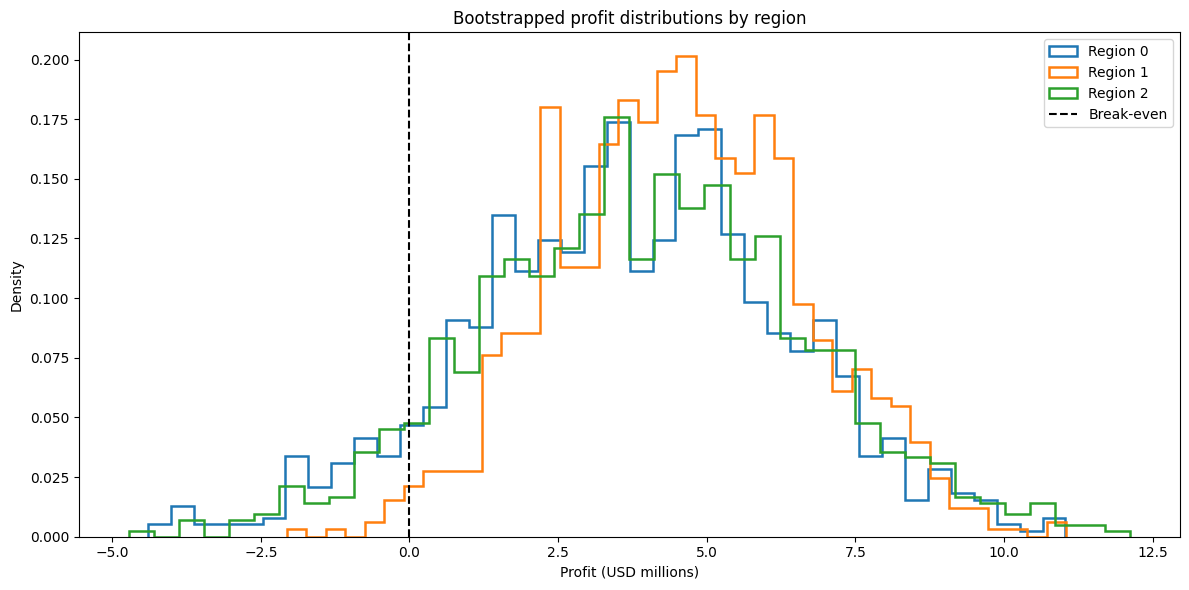

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))

for region_name, profits in bootstrap_distributions.items():
    ax.hist(profits / 1_000_000, bins=40, density=True,
            histtype="step", linewidth=1.8, label=region_name)

ax.axvline(0, color="black", linestyle="--", linewidth=1.5, label="Break-even")
ax.set_title("Bootstrapped profit distributions by region")
ax.set_xlabel("Profit (USD millions)")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
eligible_regions = risk_comparison[
    risk_comparison["Loss risk (%)"] < MAX_LOSS_RISK
]

if eligible_regions.empty:
    recommended_region = None
    print("No region meets the maximum acceptable loss-risk criterion.")
else:
    recommended_region = eligible_regions["Mean profit (USD)"].idxmax()
    print(f"Recommended region: {recommended_region}")
    print(f"Mean simulated profit: ${eligible_regions.loc[recommended_region, 'Mean profit (USD)']:,.2f}")
    print(f"Estimated loss risk: {eligible_regions.loc[recommended_region, 'Loss risk (%)']:.2f}%")

Recommended region: Region 1
Mean simulated profit: $4,550,162.58
Estimated loss risk: 1.00%


# **8. Conclusão Final**

O estudo comparou três regiões para apoiar a decisão de expansão da OilyGiant. Foram utilizados modelos de regressão linear para estimar as reservas dos poços e uma estratégia de seleção baseada nas 200 maiores previsões. A avaliação financeira considerou o orçamento de 100 milhões e a receita de 4.500 por unidade de produto.

A média de reservas de todas as regiões ficou abaixo do ponto de equilíbrio por poço, reforçando a necessidade de selecionar os locais com maior potencial. A análise pontual dos 200 poços mais bem classificados oferece uma primeira estimativa de rentabilidade, mas não captura sozinha a incerteza do investimento.

A recomendação final é determinada pela simulação de *Bootstrapping*: primeiro são descartadas as regiões cujo risco de prejuízo não seja inferior a 2,5%; entre as regiões elegíveis, escolhe-se aquela com maior lucro médio simulado. Os valores finais e a região recomendada são apresentados nas tabelas e na saída da seção anterior.

**Conclusão de negócio:** a melhor decisão não é necessariamente a região com maior volume médio de reservas ou maior lucro em um cenário isolado. É a região que combina retorno esperado mais alto com risco de prejuízo dentro do limite definido pela empresa.

## **Limitações**

- Os dados são sintéticos e não incluem custos operacionais, contratos, logística, impostos ou características adicionais dos poços.
- O modelo utiliza apenas três características geológicas e regressão linear, conforme as restrições do projeto.
- As estimativas de lucro dependem das premissas financeiras fornecidas e não devem ser interpretadas como garantia de retorno real.
- O *Bootstrapping* estima a variabilidade com base na amostra de validação disponível; sua qualidade depende de essa amostra representar adequadamente os poços da região.

## **Competências demonstradas**

Data Preparation | Linear Regression | Predictive Modeling | RMSE Evaluation | Business Analytics | Profitability Analysis | Bootstrapping | Risk Assessment | Data Visualization